# 01 Exploratory data analysis: NYC flights 2013

Dataset: 336,776 domestic departures from EWR, JFK and LGA in 2013 (Kaggle copy of `nycflights13`).
Goal of this notebook: understand the target, check data quality, and look for patterns that motivate the features
built in `02_feature_engineering.ipynb`. Figures used in the report are saved to `results/figures/`.

In [1]:
import numpy as np
import pandas as pd

In [2]:
from pathlib import Path

ROOT = Path("..").resolve()
RAW_CSV = ROOT / "data_raw" / "flights.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
TABLE_DIR = RESULTS_DIR / "tables"
for d in (PROCESSED_DIR, MODEL_DIR, FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY, LIGHT_GREY = "#8c8b86", "#c9c8c2"
TEXT, TEXT_2 = "#0b0b0b", "#52514e"
MODEL_COLORS = {"Prior rate": LIGHT_GREY, "Route history": GREY, "LR": BLUE, "XGBoost": ORANGE}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.labelcolor": TEXT_2, "axes.edgecolor": LIGHT_GREY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "lines.linewidth": 2, "legend.frameon": False, "text.color": TEXT,
})

In [4]:
DELAY_THRESHOLD = 15          # minutes, BTS definition of a delayed arrival
TRAIN_END = "2013-09-30"      # train: Jan-Sep
VAL_END = "2013-11-30"        # validation: Oct-Nov, test: Dec

# only known once the plane has left the gate, so never used as inputs
POST_DEPARTURE_COLS = ["dep_time", "dep_delay", "arr_time", "arr_delay", "air_time"]


def assign_split(dates):
    split = pd.Series("test", index=dates.index)
    split[dates <= VAL_END] = "val"
    split[dates <= TRAIN_END] = "train"
    return split


def load_raw(path=RAW_CSV):
    df = pd.read_csv(path)
    df["date"] = pd.to_datetime(df[["year", "month", "day"]])
    df["route"] = df["origin"] + "-" + df["dest"]
    # missing arr_delay = cancelled or diverted: kept for schedule counts, not used as examples
    df["no_arrival"] = df["arr_delay"].isna()
    df["delayed"] = (df["arr_delay"] >= DELAY_THRESHOLD).astype(int)
    df["split"] = assign_split(df["date"])
    return df.sort_values(["date", "sched_dep_time", "id"]).reset_index(drop=True)

In [5]:
df = load_raw()
df.shape

(336776, 26)

In [6]:
df.head()

,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,...,distance,hour,minute,time_hour,name,date,route,no_arrival,delayed,split
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,...,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.,2013-01-01,EWR-IAH,False,0,train
1,1,2013,1,1,533.0,529,4.0,850.0,830,20.0,...,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.,2013-01-01,LGA-IAH,False,1,train
2,2,2013,1,1,542.0,540,2.0,923.0,850,33.0,...,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.,2013-01-01,JFK-MIA,False,1,train
3,3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,...,1576,5,45,2013-01-01 05:00:00,JetBlue Airways,2013-01-01,JFK-BQN,False,0,train
4,5,2013,1,1,554.0,558,-4.0,740.0,728,12.0,...,719,5,58,2013-01-01 05:00:00,United Air Lines Inc.,2013-01-01,EWR-ORD,False,0,train


## 1. Data quality

In [7]:
missing = df.isna().sum()
missing[missing > 0].to_frame("missing").assign(share=lambda t: (t["missing"] / len(df)).round(4))

,missing,share
dep_time,8255,0.0245
dep_delay,8255,0.0245
arr_time,8713,0.0259
arr_delay,9430,0.0280
tailnum,2512,0.0075
air_time,9430,0.0280


In [8]:
cancelled = df["dep_time"].isna()
diverted = df["dep_time"].notna() & df["arr_delay"].isna()
print(f"cancelled (no departure):            {cancelled.sum():,}")
print(f"departed but no arrival (diverted):  {diverted.sum():,}")
print(f"duplicate ids:                       {df['id'].duplicated().sum()}")
print(f"carriers: {df.carrier.nunique()}, origins: {df.origin.nunique()}, destinations: {df.dest.nunique()}, aircraft: {df.tailnum.nunique()}")

cancelled (no departure):            8,255
departed but no arrival (diverted):  1,175
duplicate ids:                       0
carriers: 16, origins: 3, destinations: 105, aircraft: 4043


Missing values come only from cancelled or diverted flights (no arrival, so no arrival delay) and a few
missing tail numbers. Flights without `arr_delay` cannot be labelled, so they are dropped as training
examples, but they are kept when counting the scheduled volume because the schedule is known in advance.

## 2. Target: arrival delay of 15+ minutes

delayed share: 0.245


count    327346.0
mean          6.9
std          44.6
min         -86.0
25%         -17.0
50%          -5.0
75%          14.0
max        1272.0
Name: arr_delay, dtype: float64

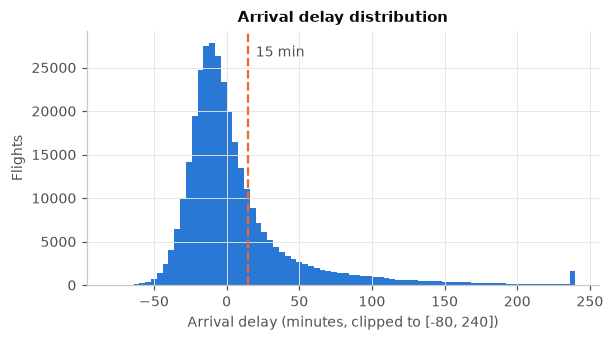

In [9]:
obs = df[~df["no_arrival"]]
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(obs["arr_delay"].clip(-80, 240), bins=80, color=BLUE)
ax.axvline(DELAY_THRESHOLD, color=ORANGE, lw=1.5, ls="--")
ax.text(DELAY_THRESHOLD + 5, ax.get_ylim()[1] * 0.9, "15 min", color=TEXT_2)
ax.set(xlabel="Arrival delay (minutes, clipped to [-80, 240])", ylabel="Flights", title="Arrival delay distribution")
fig.savefig(FIG_DIR / "eda_arr_delay.png")
print(f"delayed share: {obs['delayed'].mean():.3f}")
obs["arr_delay"].describe().round(1)

The distribution is very right-skewed: most flights arrive early or on time and a long tail is hours late.
Using the BTS definition (15+ minutes late) gives a binary target with roughly a quarter positives, so the classes
are imbalanced and PR-AUC is a more informative headline metric than accuracy.

## 3. Leakage check: departure delay

In [10]:
print(obs[["dep_delay", "arr_delay"]].corr().round(3))
print("post-departure columns removed from the features:", POST_DEPARTURE_COLS)

           dep_delay  arr_delay
dep_delay      1.000      0.915
arr_delay      0.915      1.000
post-departure columns removed from the features: ['dep_time', 'dep_delay', 'arr_time', 'arr_delay', 'air_time']


Departure delay and arrival delay have a correlation above 0.9. A model given `dep_delay` would look
excellent but would be useless before departure, so it and the other post-departure fields are never used.

## 4. Seasonality and the chronological split

,size,mean
split,,
test,27020,0.335
train,244737,0.250
val,55589,0.178


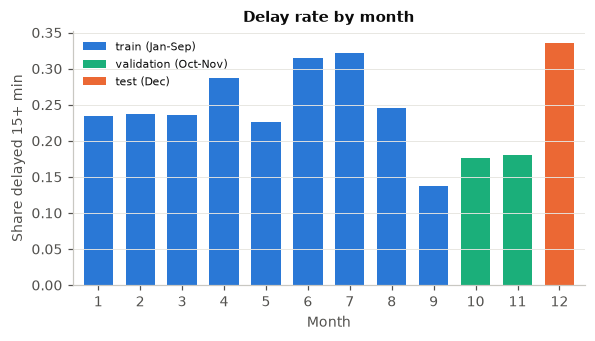

In [11]:
monthly = obs.groupby("month")["delayed"].mean()
split_of_month = obs.groupby("month")["split"].first()
colors = split_of_month.map({"train": BLUE, "val": AQUA, "test": ORANGE})
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(monthly.index, monthly.values, color=colors.values, width=0.7)
for s, c in (("train (Jan-Sep)", BLUE), ("validation (Oct-Nov)", AQUA), ("test (Dec)", ORANGE)):
    ax.bar([0], [0], color=c, label=s)
ax.set(xlabel="Month", ylabel="Share delayed 15+ min", title="Delay rate by month", xticks=range(1, 13), xlim=(0.4, 12.6))
ax.legend(loc="upper left", fontsize=7.5)
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "eda_month.png")
obs.groupby("split")["delayed"].agg(["size", "mean"]).round(3)

Delay rates move a lot between months (summer storms in Jun-Jul, holiday travel and winter weather in December,
calm Sep-Nov). The validation months (about 18% delayed) are among the calmest of the year while December (34%) is the worst,
so the base rate shifts between splits. This matters for calibration (see report) and is why month or
day-of-year features are not used: the test months never appear in training.

## 5. Time of day and day of week

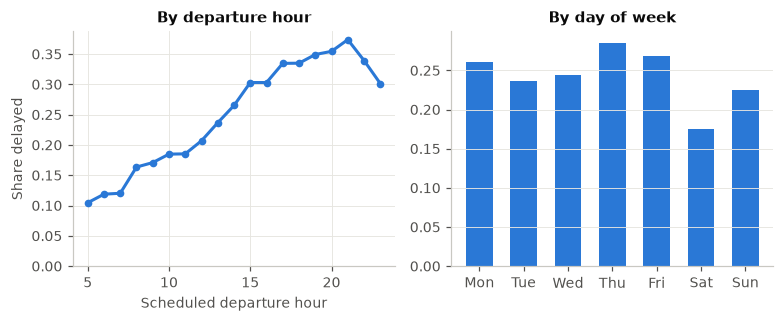

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3))
by_hour = obs.groupby("hour")["delayed"].agg(["mean", "size"])
by_hour = by_hour[by_hour["size"] >= 200]
axes[0].plot(by_hour.index, by_hour["mean"], marker="o", ms=4, color=BLUE)
axes[0].set(xlabel="Scheduled departure hour", ylabel="Share delayed", title="By departure hour", ylim=(0, None))
by_dow = obs.groupby(obs["date"].dt.day_name())["delayed"].mean()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
axes[1].bar([d[:3] for d in order], by_dow.loc[order].values, color=BLUE, width=0.6)
axes[1].set(title="By day of week", ylim=(0, None))
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_hour_dow.png")

The delay rate rises steadily from early morning to evening: delays propagate through the day as aircraft
and crews run late on earlier legs. This is the strongest schedule signal, and it motivates the cyclic
departure-time encoding, the `tail_day_leg` feature and the "move earlier" moves in the rescheduling analysis.
Saturday is noticeably better than weekdays.

## 6. Carrier, origin and route

,mean,size
origin,,
EWR,0.263,117127
JFK,0.237,109079
LGA,0.231,101140


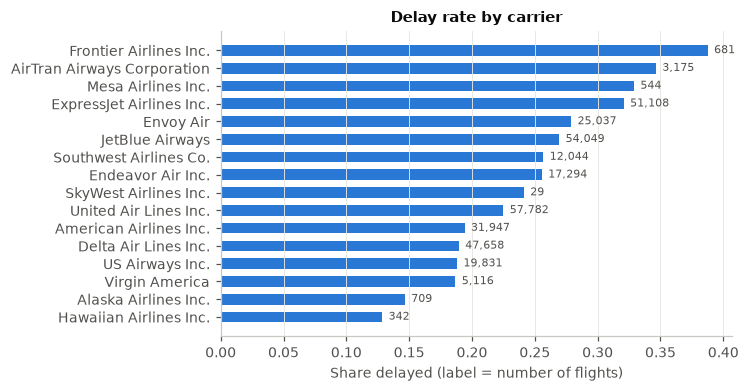

In [13]:
by_carrier = obs.groupby("name")["delayed"].agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.barh(by_carrier.index, by_carrier["mean"], color=BLUE, height=0.6)
for i, (m, n) in enumerate(zip(by_carrier["mean"], by_carrier["size"])):
    ax.text(m + 0.005, i, f"{n:,}", va="center", fontsize=7, color=TEXT_2)
ax.set(xlabel="Share delayed (label = number of flights)", title="Delay rate by carrier")
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "eda_carrier.png")
obs.groupby("origin")["delayed"].agg(["mean", "size"]).round(3)

In [14]:
route = obs.groupby("route")["delayed"].agg(["mean", "size"])
print(f"{len(route)} routes; median flights per route: {route['size'].median():.0f}; routes with < 50 flights: {(route['size'] < 50).sum()}")
route[route["size"] >= 500].sort_values("mean").iloc[[0, 1, 2, -3, -2, -1]].round(3)

223 routes; median flights per route: 752; routes with < 50 flights: 23


,mean,size
route,,
LGA-BOS,0.145,4002
EWR-RSW,0.154,1424
EWR-SNA,0.161,812
EWR-DCA,0.393,1567
EWR-MEM,0.398,845
EWR-RIC,0.407,1615


Among carriers with at least 1,000 flights the delay rate ranges from about 19% (US Airways, Delta) to 35%
(AirTran); the extremes of the chart are small carriers with few flights. Routes vary from about 15% to 40%,
but many routes and individual flight numbers have few observations. That is why the historical rates in notebook 02 are smoothed towards
the system-wide rate (`m = 20` pseudo-flights) instead of using raw averages.

## 7. Day-to-day persistence

{1: np.float64(0.398), 2: np.float64(0.128), 7: np.float64(0.112)}


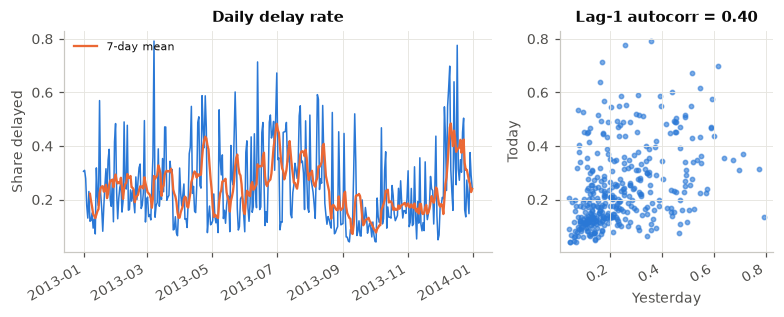

In [15]:
daily = obs.groupby("date")["delayed"].mean()
lag1 = daily.autocorr(1)
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(daily.index, daily.values, color=BLUE, lw=1)
axes[0].plot(daily.rolling(7).mean().index, daily.rolling(7).mean().values, color=ORANGE, lw=1.5, label="7-day mean")
axes[0].set(ylabel="Share delayed", title="Daily delay rate")
axes[0].legend(loc="upper left", fontsize=7.5)
axes[1].scatter(daily.shift(1), daily, s=8, color=BLUE, alpha=0.6)
axes[1].set(xlabel="Yesterday", ylabel="Today", title=f"Lag-1 autocorr = {lag1:.2f}")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_daily.png")
print({k: round(daily.autocorr(k), 3) for k in (1, 2, 7)})

Bad days cluster: weather systems and knock-on disruption can last more than one day, so yesterday's delay
rate carries information about today (lag-1 autocorrelation about 0.4). The effect fades quickly, though:
at lag 2 and lag 7 it is close to 0.1. This motivates the "recent history" features (previous-day and 7-day
rates), all computed from strictly earlier dates. Most of the day-to-day variation is still unexplained
because the dataset has no weather forecast, which caps how well any pre-departure model can do.

## 8. Distance and congestion

In [16]:
bins = pd.qcut(obs["distance"], 10)
dist = obs.groupby(bins, observed=True)["delayed"].mean()
vol = obs.groupby(["origin", "date"]).agg(flights=("id", "size"), delayed=("delayed", "mean"))
print("delay rate by distance decile:", dist.round(3).tolist())
print("corr(daily flights at origin, daily delay rate):", round(vol["flights"].corr(vol["delayed"]), 3))

delay rate by distance decile: [0.231, 0.267, 0.247, 0.262, 0.276, 0.245, 0.234, 0.238, 0.223, 0.221]
corr(daily flights at origin, daily delay rate): 0.057


Distance has only a weak relationship with delay. The number of scheduled departures per airport per day
is a congestion proxy that is known in advance. Its raw daily correlation with the delay rate is weak, but it
also encodes the weekly and seasonal schedule pattern, and the models use it in combination with other features.

## Summary of findings used in modelling
* Target: `arr_delay >= 15`; cancelled/diverted flights dropped from training (kept for schedule counts).
* Post-departure fields are removed (`dep_delay` alone almost determines the label).
* Strong time-of-day effect and carrier/route effects -> cyclic time, categorical and smoothed historical-rate features.
* Delays persist across days -> previous-day and 7-day features from strictly earlier dates.
* Strong month-to-month variation and a calm validation period vs. a bad test month -> chronological split, no month features, careful calibration.